In [1]:
## IMPORT LIBRARIES 
import os 
import numpy as np
import spikeinterface.core as si 
import spikeinterface.widgets as sw
import spikeinterface.extractors as se
from spikeinterface.extractors import read_phy
from spikeinterface.preprocessing import common_reference
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm import tqdm

/u/gongt/conda-envs/spikeinterface/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
### PARAMETERS ### 
root_folder = r"/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0" 
exp_folder = os.path.join(root_folder, 'ms5', 'ms5_p1r-None_r-None_p1thr-4.5_thr-3.5_sgn-0_p1pc-6_T1-30_T2-30')
sorter_output = os.path.join(exp_folder, 'phy')
preprocessed_folder = os.path.join(root_folder, 'preprocessed_slice_550_1270s')
analyzer_save = os.path.join(exp_folder, 'si_analyzer')

preprocessed_rec = si.load(preprocessed_folder)
preprocessed_rec

fs = preprocessed_rec.get_sampling_frequency()
nchan = preprocessed_rec.get_num_channels()

ks_preprocessed_file = os.path.join(sorter_output, "temp_wh.dat")
ks_preprocessed_rec = si.load_extractor(preprocessed_folder)

sorting = read_phy(sorter_output)

/tmp/ipykernel_47710/808419899.py:15: DeprecationWarning: load_extractor() is deprecated and will be removed in version 0.104.0. Please use load() instead.
  ks_preprocessed_rec = si.load_extractor(preprocessed_folder)


## SPIKE OVER TRACE

In [4]:
spike_clusters = np.load(os.path.join(sorter_output, 'spike_clusters.npy'))
#spike_positions = np.load(os.path.join(sorter_output, 'spike_positions.npy'))
spike_templates = np.load(os.path.join(sorter_output,'spike_templates.npy'))
templates = np.load(os.path.join(sorter_output,'templates.npy'))
channel_positions = np.load(os.path.join(sorter_output,'channel_positions.npy'))
channel_map = np.load(os.path.join(sorter_output,'channel_map.npy')) 
spike_times = np.load(os.path.join(sorter_output, 'spike_times.npy'))
#ops = np.load(os.path.join(sorter_output, 'ops.npy'), allow_pickle = True)
#fs = ops.item()['fs']
pc_features = np.load(os.path.join(sorter_output, 'pc_features.npy'))  #shape: n_spikes * n_pcs * nearest_chans
pc_feature_ind = np.load(os.path.join(sorter_output, 'pc_feature_ind.npy')) #shape: 145 * nearest_chans


In [5]:
print(spike_clusters.shape)
print(len(pc_features[0][0]))
print(len(pc_feature_ind[0]))

(182496, 1)
18
18


In [6]:
def plot_spikes_on_trace(rec, preprocessed_rec, templates, spike_templates, spike_times, spike_clusters, fs, active_channel_threshold, time_range, sorter_output, rec_name): 
    ### find best channel for each spike ### 
    template_amplitudes = np.max(np.abs(templates),axis=1) #n_templates, n_channels 
    peak_channels_for_template = np.argmax(template_amplitudes, axis = 1) #n_templates

    #map spikes to its template's peak channel 
    all_spike_template_indices = spike_templates.flatten() 
    all_spike_peak_channel = peak_channels_for_template[all_spike_template_indices]

    ### time window filtering ### 
    start_samp = time_range[0]*fs
    end_samp = time_range[1]*fs
    # find a mask to filter only spikes in this time window 
    in_window = (spike_times.flatten() > start_samp) & (spike_times.flatten() < end_samp)
    in_window_spike_times = spike_times.flatten()[in_window]
    in_window_spike_clusters = spike_clusters.flatten()[in_window]
    in_window_spike_peak_channels = all_spike_peak_channel[in_window]
    in_window_spike_template_indices = all_spike_template_indices[in_window]

    print(f"Number of spikes in window: {len(in_window_spike_peak_channels)}")
    print(f"Spike times shape: {in_window_spike_times.shape}")

    active_channels_mask = template_amplitudes > active_channel_threshold
    active_channel_counts = np.sum(active_channels_mask, axis = 1) 
    max_channel_count = np.max(active_channel_counts)
    template_index_max_channels = np.argmax(active_channel_counts)

    sampling_freq = rec.get_sampling_frequency()  
    channels = rec.get_channel_ids()
    sample_window = 32
    scale = 3
    shading_amplitude_threshold = active_channel_threshold
    time_range = list(time_range)
    
    start_frame = int(time_range[0] * sampling_freq)
    end_frame = int(time_range[1] * sampling_freq)

    traces = rec.get_traces(channel_ids=channels, segment_index=0, start_frame=start_frame, end_frame=end_frame)
    traces = traces * scale

    vspacing = np.max(np.abs(traces)) * 1.2  
    offsets = np.arange(traces.shape[1]) * vspacing
    traces_offset = traces + offsets
    time_vec = np.arange(start_frame, end_frame) / sampling_freq

    plt.figure(figsize=(20, 90))
    for ch in range(traces.shape[1]):
        plt.plot(time_vec, traces_offset[:, ch], color='black', lw=0.5)

    clusters = np.unique(in_window_spike_clusters)
    n_colors = len(clusters)
    cmap = plt.cm.get_cmap('tab20', 100) 

    color_indices = []
    step = 5 
    for i in range(n_colors):
        color_index = (i * step) % cmap.N 
        color_indices.append(color_index)

    cluster_color_dict = {}
    for i, unit_id in enumerate(clusters):
        color = cmap(color_indices[i])
        cluster_color_dict[unit_id] = color

    iterator = zip(
        in_window_spike_times, 
        in_window_spike_peak_channels, 
        in_window_spike_clusters, 
        in_window_spike_template_indices 
    )
    total_channels = len(channels) 

    for st, ch_peak, cl, template_idx in tqdm(iterator, total=len(in_window_spike_times)):
        st_s = st / fs  # convert to seconds
        current_template_amplitudes = template_amplitudes[template_idx, :]
        for c in range(total_channels): 
            if current_template_amplitudes[c] > shading_amplitude_threshold:
                rect = patches.Rectangle(
                    (st_s - sample_window/fs, offsets[c] - vspacing*0.49),  # (x, y)
                    2*sample_window/fs,                                      # width
                    vspacing*0.93,                                           # height
                    color=cluster_color_dict[cl],
                    alpha=0.3
                )
                plt.gca().add_patch(rect)

    channel_string_ids = preprocessed_rec.get_channel_ids()

    plt.ylim(offsets[0] - vspacing*0.5, offsets[-1] + vspacing*0.5)
    plt.xlabel('Time (s)')
    plt.ylabel('Channels (offset)')
    plt.title(f'Raw traces with cluster spike highlights (Template Amplitude > {shading_amplitude_threshold})')
    plt.yticks(offsets, channel_string_ids)

    plt.savefig(os.path.join(sorter_output, f'trace_visualise_{rec_name}_{shading_amplitude_threshold}_{time_range[0]}_{time_range[1]}.png'))
    plt.show()

Number of spikes in window: 17
Spike times shape: (17,)


/tmp/ipykernel_47710/4062517658.py:52: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('tab20', 100)
  0%|          | 0/17 [00:00<?, ?it/s]


IndexError: index 18 is out of bounds for axis 0 with size 18

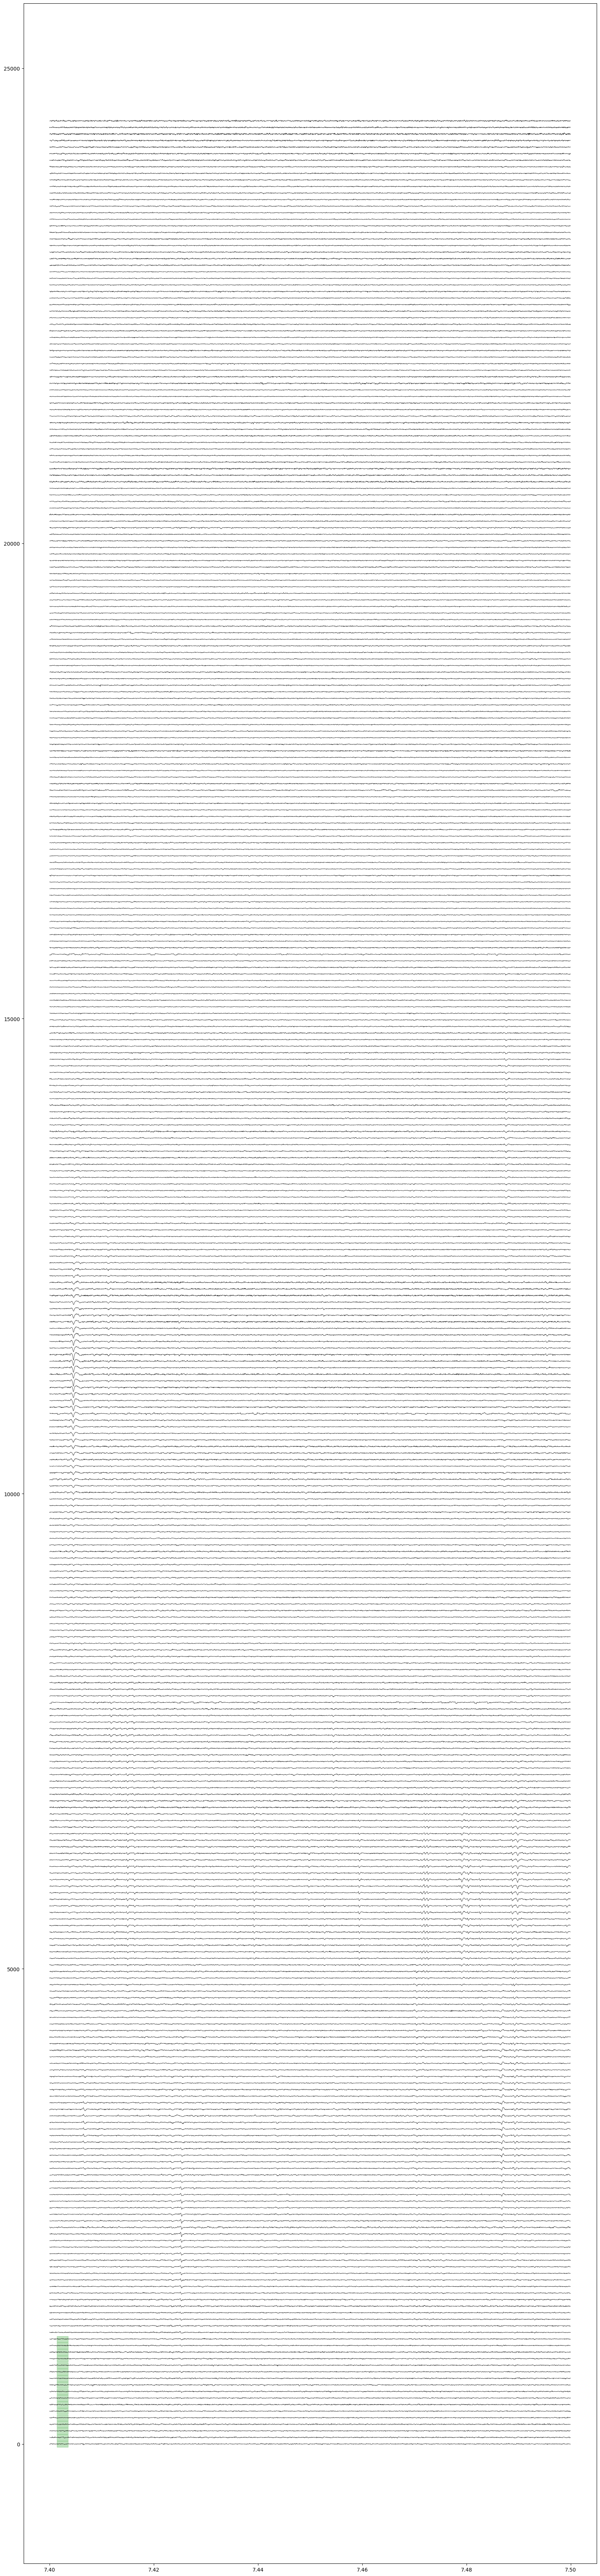

In [7]:
active_channel_threshold = 0.1
time_range = (7.4, 7.5)
plot_spikes_on_trace(ks_preprocessed_rec, preprocessed_rec, templates, spike_templates, spike_times, spike_clusters, fs, active_channel_threshold, time_range, sorter_output, rec_name = 'kspreprocessed')

## COMPUTE MAX CHANNEL

In [8]:
print(len(templates))

7


In [9]:
def get_closest_channels(channel_positions, channel_index, n=None):
    x = channel_positions[:, 0]
    y = channel_positions[:, 1]
    x0, y0 = channel_positions[channel_index]
    d = (x - x0) ** 2 + (y - y0) ** 2
    out = np.argsort(d)
    if n:
        out = out[:n]
    assert out[0] == channel_index 
    return out 

In [10]:
import numpy as np
import os

n_closest_channels = 6

for unit_id in range(len(templates)): 
    print(unit_id)
    unit_template = templates[unit_id]
    amplitude = unit_template.max(axis=0) - unit_template.min(axis=0)
    best_channel = np.argmax(amplitude)
    print(f"Unit {unit_id}: Max Channel Index (in template array) = {best_channel}")

    max_amp = amplitude[best_channel]
    amplitude_threshold = 0
    peak_channels = np.nonzero(amplitude >= amplitude_threshold * max_amp)[0]

    close_channels = get_closest_channels(
        channel_positions, best_channel, n_closest_channels)
    assert best_channel in close_channels

    channel_ids = np.intersect1d(peak_channels, close_channels)

    order = np.argsort(amplitude[channel_ids])[::-1]
    channel_ids = channel_ids[order]
    amplitude = amplitude[order]
    assert best_channel in channel_ids
    assert amplitude.shape == (len(channel_ids),)
    print(channel_ids, amplitude, best_channel)

0
Unit 0: Max Channel Index (in template array) = 9
[ 9 12  5  7  8 10] [20.28515625 27.3203125  18.8671875  19.4921875  19.890625   21.79296875] 9
1
Unit 1: Max Channel Index (in template array) = 9
[ 9  7 10  8  5 12] [10.2421875   8.63867188 11.06835938  9.76953125  8.52539062 13.96679688] 9
2
Unit 2: Max Channel Index (in template array) = 9
[ 9  8  7  5 10 12] [12.68164062 12.44921875 12.34179688 10.72851562 14.61132812 15.25195312] 9
3
Unit 3: Max Channel Index (in template array) = 9
[ 9  7  5 12  8 10] [12.12109375  9.9453125   8.20996094 13.828125    9.83984375 11.80273438] 9
4
Unit 4: Max Channel Index (in template array) = 8
[ 8 10  7  6  9  4] [40.734375  51.5546875 40.8125    37.0390625 46.4375    35.96875  ] 8
5
Unit 5: Max Channel Index (in template array) = 8
[ 8  4  7 10  6  9] [10.71289062  9.29492188  8.36132812 10.56445312  8.640625   11.13867188] 8
6
Unit 6: Max Channel Index (in template array) = 8
[ 8  4 10  6  7  9] [13.3046875  11.9453125  13.05859375 12.824218

In [11]:
import numpy as np
import os

for unit_id in range(len(templates)): 
    print(unit_id)
    unit_template = templates[unit_id]
    amplitude = unit_template.max(axis=0) - unit_template.min(axis=0)
    best_channel = np.argmax(amplitude)
    print(f"Unit {unit_id}: Max Channel Index (in template array) = {best_channel}")

0
Unit 0: Max Channel Index (in template array) = 9
1
Unit 1: Max Channel Index (in template array) = 9
2
Unit 2: Max Channel Index (in template array) = 9
3
Unit 3: Max Channel Index (in template array) = 9
4
Unit 4: Max Channel Index (in template array) = 8
5
Unit 5: Max Channel Index (in template array) = 8
6
Unit 6: Max Channel Index (in template array) = 8


In [12]:
import numpy as np
import os

for unit_id in range(len(templates)): 
    print(unit_id)
    unit_template = templates[unit_id]
    channel_energy = np.sum(unit_template**2, axis=0) # Shape: (n_channels,)
    max_channel_index = np.argmax(channel_energy)
    print(f"Unit {unit_id}: Max Channel Index (in template array) = {max_channel_index}")

0
Unit 0: Max Channel Index (in template array) = 9
1
Unit 1: Max Channel Index (in template array) = 9
2
Unit 2: Max Channel Index (in template array) = 9
3
Unit 3: Max Channel Index (in template array) = 9
4
Unit 4: Max Channel Index (in template array) = 8
5
Unit 5: Max Channel Index (in template array) = 8
6
Unit 6: Max Channel Index (in template array) = 8


In [ ]:
def smart_compute(analyzer_save, compute_dict, sorting):
    if os.path.exists(analyzer_save):
        print("analyzer folder exists, loading extensions...")
        sorting_analyzer = si.load_sorting_analyzer(folder = analyzer_save, format = 'binary_folder')
    else: 
        print("analyzer folder does not exist, creating new analyzer...")
        sorting_analyzer = si.create_sorting_analyzer(sorting = sorting, recording = preprocessed_rec, format = 'binary_folder', folder = analyzer_save, sparse=False)
    
    existing_exts = sorting_analyzer.get_loaded_extension_names()
    print("already available:", existing_exts)
    '''
    print("computing sparsity...")
    sparsity = si.compute_sparsity(sorting_analyzer, method = 'closest_channels', num_channels = 48)
    print("finished computing sparsity")
    '''
    compute_dict = {
    'random_spikes': {}, #random spike selection across units 
    'waveforms':{},
    'principal_components':{'n_components': 6, 'whiten':False},
    }

    to_compute = {
        ext: params for ext, params in compute_dict.items() if ext not in existing_exts
    }
    print("need to compute:", list(to_compute.keys()))

    if len(to_compute) > 0: 
        print("computing...")
        sorting_analyzer.compute(to_compute, save = True, progress_bar = True, n_jobs = -1)
    
    return sorting_analyzer 

In [21]:
sorting_analyzer = smart_compute(analyzer_save, compute_dict, sorting) 

analyzer folder does not exist, creating new analyzer...


estimate_sparsity (no parallelization):   0%|          | 0/2681 [00:00<?, ?it/s]

/u/gongt/.local/lib/python3.10/site-packages/spikeinterface/core/sortinganalyzer.py:377: UserWarning: Your sorting has spikes with samples times greater than your recording length. These spikes have been removed.
  warnings.warn(


already available: []
computing sparsity...


IndexError: index 355 is out of bounds for axis 0 with size 355

In [ ]:
from spikeinterface.exporters import export_to_phy
export_to_phy(sorting_analyzer=sorting_analyzer, 
              output_folder= os.path.join(exp_folder, 'export_to_phy'),
              copy_binary = False, 
              remove_if_exists = True,
              n_jobs = 8
              )

extract PCs (workers: 8 processes): 100%|██████████| 2681/2681 [07:21<00:00,  6.08it/s]


Run:
phy template-gui  E:\GLC6962_c_g0\KS4\nc32_wr64_thu9_thl8\export_to_phy\params.py


In [4]:
### PARAMETERS ### 
root_folder = r"/nexus/posix0/MBR-neuralsystems/ephys/GLC6962/GLC6962_g_g0"  
exp_folder = os.path.join(root_folder, 'KS4', 'nc10_wr0')
sorter_output = os.path.join(exp_folder, 'sorter_output')
preprocessed_folder = os.path.join(root_folder, 'preprocessed')
analyzer_save = os.path.join(exp_folder, 'si_analyzer')

preprocessed_rec = si.load(preprocessed_folder)
preprocessed_rec

fs = preprocessed_rec.get_sampling_frequency()
nchan = preprocessed_rec.get_num_channels()

ks_preprocessed_file = os.path.join(sorter_output, "temp_wh.dat")
ks_preprocessed_rec = si.load_extractor(preprocessed_folder)

sorting = read_phy(sorter_output)

/tmp/ipykernel_126087/633855854.py:15: DeprecationWarning: load_extractor() is deprecated and will be removed in version 0.104.0. Please use load() instead.
  ks_preprocessed_rec = si.load_extractor(preprocessed_folder)


In [6]:
spike_clusters = np.load(os.path.join(sorter_output, 'spike_clusters.npy'))
#spike_positions = np.load(os.path.join(sorter_output, 'spike_positions.npy'))
spike_templates = np.load(os.path.join(sorter_output,'spike_templates.npy'))
templates = np.load(os.path.join(sorter_output,'templates.npy'))
channel_positions = np.load(os.path.join(sorter_output,'channel_positions.npy'))
channel_map = np.load(os.path.join(sorter_output,'channel_map.npy')) 
spike_times = np.load(os.path.join(sorter_output, 'spike_times.npy'))
ops = np.load(os.path.join(sorter_output, 'ops.npy'), allow_pickle = True)
fs = ops.item()['fs']
pc_features = np.load(os.path.join(sorter_output, 'pc_features.npy'))  #shape: n_spikes * n_pcs * nearest_chans
pc_feature_ind = np.load(os.path.join(sorter_output, 'pc_feature_ind.npy')) #shape: 145 * nearest_chans


In [7]:
print(len(pc_features[0][0]))

10
